In [13]:
!nvidia-smi

Sun Nov 15 22:01:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.57.01              KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4080        On  |   00000000:01:00.0  On |                  N/A |
|  0%   39C    P8             12W /  320W |     838MiB /  16376MiB |     16%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [14]:
from numba import cuda, float64, int64
from numba.cuda.random import create_xoroshiro128p_states
from numba.cuda.random import xoroshiro128p_normal_float32
from numba.cuda.random import xoroshiro128p_uniform_float32

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pandas as pd
import numpy as np
import math
import time

In [15]:
L = 64
N = L * L
J = 1.0

q0 = np.pi / 4
D = J * np.tan(q0)
J2 = J / (4 * np.cos(q0))
B_z = 0.0

replicas = 32
adapt_every = 500
sample_every = 1000

seed_dmi = 2026
seed_frustration = 2027

n_therm = 500000
n_measure = 1000000
sigma_initial = 0.6

T_plot = np.array([0.1, 0.3, 0.5, 1.0])
T = np.linspace(3, 0.1, 100)
T = np.sort(np.unique(np.concatenate((T, T_plot))))[::-1]

N_REPLICAS_ASD = 4
N_SAMPLES_ASD = 512
DT_ASD = 0.025
SAMPLE_EVERY_ASD = 5
BLOCK_ASD = (8, 8, 1)

In [16]:
def random_spin_field():
    spins = np.random.normal(size=(L, L, 3))
    spins /= np.linalg.norm(spins, axis=2, keepdims=True)
    return spins

np.random.seed(123)
lattice = random_spin_field()

In [ ]:
@cuda.jit
def gpu_sweeps(spins, counts, rng_states, temp, d_sigma, B_z, model_id, J, J2, D, sweeps):

    replica = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    n_per_color = (nx // 4) * (ny // 2)
    rid = replica * n_per_color + tid

    sigma = d_sigma[0]
    accepted = 0

    # eight-color lattice decomposition
    for sweep in range(sweeps):
        for color in range(8):

            cx = color // 2
            cy = color % 2

            x = 4 * (tid // (ny // 2)) + cx
            y = 2 * (tid % (ny // 2)) + cy

            xp = (x + 1) % nx
            xm = (x - 1) % nx
            yp = (y + 1) % ny
            ym = (y - 1) % ny

            old_x = spins[replica, x, y, 0]
            old_y = spins[replica, x, y, 1]
            old_z = spins[replica, x, y, 2]

            tx = old_x + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            ty = old_y + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            tz = old_z + sigma * xoroshiro128p_normal_float32(rng_states, rid)

            norm = math.sqrt(tx*tx + ty*ty + tz*tz)

            if norm > 0.0:
                tx /= norm
                ty /= norm
                tz /= norm

                dx = tx - old_x
                dy = ty - old_y
                dz = tz - old_z

                n0 = (spins[replica, xp, y, 0] + spins[replica, xm, y, 0] + spins[replica, x, yp, 0] + spins[replica, x, ym, 0])

                n1 = (spins[replica, xp, y, 1] + spins[replica, xm, y, 1] + spins[replica, x, yp, 1] + spins[replica, x, ym, 1])

                n2 = (spins[replica, xp, y, 2] + spins[replica, xm, y, 2] + spins[replica, x, yp, 2] + spins[replica, x, ym, 2])

                dE = -J * (dx*n0 + dy*n1 + dz*n2) - B_z*dz

                if model_id == 1:
                    xpp = (x + 2) % nx
                    xmm = (x - 2) % nx

                    dE += J2 * (dx * (spins[replica, xpp, y, 0] + spins[replica, xmm, y, 0]) + dy * (spins[replica, xpp, y, 1] + spins[replica, xmm, y, 1]) + dz * (spins[replica, xpp, y, 2] + spins[replica, xmm, y, 2]))

                else:

                    ax1 = (spins[replica, xp, y, 2] - spins[replica, xm, y, 2])

                    ax2 = -(spins[replica, xp, y, 1] - spins[replica, xm, y, 1])

                    dE -= D * (dy*ax1 + dz*ax2)

                if dE <= 0.0 or (temp > 0.0 and xoroshiro128p_uniform_float32(rng_states, rid) < math.exp(-dE/temp)):
                    spins[replica, x, y, 0] = tx
                    spins[replica, x, y, 1] = ty
                    spins[replica, x, y, 2] = tz
                    accepted += 1

            cuda.syncthreads()

    counts[replica, tid] = accepted


In [18]:
@cuda.jit
def measure_gpu(spins, energies, magnetizations, B_z, model_id, J, J2, D):

    r = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    sh_e = cuda.shared.array(256, dtype=float64)
    sh_mx = cuda.shared.array(256, dtype=float64)
    sh_my = cuda.shared.array(256, dtype=float64)
    sh_mz = cuda.shared.array(256, dtype=float64)

    e = 0.0
    mx = 0.0
    my = 0.0
    mz = 0.0

    for k in range(tid, nx * ny, cuda.blockDim.x):
        x = k // ny
        y = k % ny

        xp = (x + 1) % nx
        yp = (y + 1) % ny

        sx = float64(spins[r, x, y, 0])
        sy = float64(spins[r, x, y, 1])
        sz = float64(spins[r, x, y, 2])

        ax = float64(spins[r, xp, y, 0])
        ay = float64(spins[r, xp, y, 1])
        az = float64(spins[r, xp, y, 2])

        bx = float64(spins[r, x, yp, 0])
        by = float64(spins[r, x, yp, 1])
        bz = float64(spins[r, x, yp, 2])

        e -= J * (sx * (ax + bx) + sy * (ay + by) + sz * (az + bz))

        e -= B_z * sz

        if model_id == 1:
            xpp = (x + 2) % nx

            e += J2 * (sx * float64(spins[r, xpp, y, 0]) + sy * float64(spins[r, xpp, y, 1]) + sz * float64(spins[r, xpp, y, 2]))

        else:
            e -= D * (sy * az - sz * ay)

        mx += sx
        my += sy
        mz += sz

    sh_e[tid] = e
    sh_mx[tid] = mx
    sh_my[tid] = my
    sh_mz[tid] = mz

    cuda.syncthreads()

    stride = cuda.blockDim.x // 2

    while stride > 0:
        if tid < stride:
            sh_e[tid] += sh_e[tid + stride]
            sh_mx[tid] += sh_mx[tid + stride]
            sh_my[tid] += sh_my[tid + stride]
            sh_mz[tid] += sh_mz[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        energies[r] = sh_e[0]
        magnetizations[r, 0] = sh_mx[0]
        magnetizations[r, 1] = sh_my[0]
        magnetizations[r, 2] = sh_mz[0]


In [19]:
@cuda.jit
def adapt_sigma_gpu(counts, d_sigma, N, sweeps):

    tid = cuda.threadIdx.x
    ncols = counts.shape[1]
    total = 0

    for i in range(tid, counts.shape[0] * ncols, 256):
        total += counts[i // ncols, i % ncols]

    sh = cuda.shared.array(256, dtype=int64)
    sh[tid] = total

    cuda.syncthreads()

    stride = 128

    while stride > 0:
        if tid < stride:
            sh[tid] += sh[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        R = sh[0] / (counts.shape[0] * N * sweeps)
        sigma = d_sigma[0] * math.exp(0.5 * (R - 0.5))
        d_sigma[0] = min(max(sigma, 1e-3), 2.0)


In [20]:

@cuda.jit
def accumulate_stats_gpu(d_energies, d_magnetizations, counts, stats):

    r = cuda.grid(1)

    if r < d_energies.shape[0]:
        n = stats[r, 0] + 1.0

        E = d_energies[r]

        delta_E = E - stats[r, 1]
        E_mean = stats[r, 1] + delta_E / n

        stats[r, 2] += delta_E * (E - E_mean)
        stats[r, 1] = E_mean

        mx = d_magnetizations[r, 0]
        my = d_magnetizations[r, 1]
        mz = d_magnetizations[r, 2]

        M_abs = math.sqrt(mx*mx + my*my + mz*mz)

        delta_M = M_abs - stats[r, 3]
        M_abs_mean = stats[r, 3] + delta_M / n

        stats[r, 4] += delta_M * (M_abs - M_abs_mean)
        stats[r, 3] = M_abs_mean
        stats[r, 0] = n

        accepted = 0

        for k in range(counts.shape[1]):
            accepted += counts[r, k]

        stats[r, 5] += accepted


In [21]:
@cuda.jit
def finalize_stats_gpu(stats, d_sigma, result, temp, N, n_measure):

    if cuda.grid(1) == 0:
        n_total = 0.0

        E_mean = 0.0
        E_m2 = 0.0

        M_abs_mean = 0.0
        M_m2 = 0.0

        accepted_sum = 0.0

        for r in range(stats.shape[0]):
            n = stats[r, 0]
            new_total = n_total + n

            delta_E = stats[r, 1] - E_mean
            delta_M = stats[r, 3] - M_abs_mean

            E_m2 += (stats[r, 2] + delta_E * delta_E * n_total * n / new_total)

            M_m2 += (stats[r, 4] + delta_M * delta_M * n_total * n / new_total)

            E_mean += delta_E * n / new_total
            M_abs_mean += delta_M * n / new_total

            n_total = new_total
            accepted_sum += stats[r, 5]

        result[0] = E_m2 / (n_total * N * temp ** 2)
        result[1] = M_m2 / (n_total * N * temp)
        result[2] = M_abs_mean
        result[3] = E_mean
        result[4] = accepted_sum / (stats.shape[0] * N * n_measure)
        result[5] = d_sigma[0]

In [22]:
def simulate_temp(lattice, T, B_z, model, replicas, adapt_every, sample_every, seed, n_therm_run, n_measure_run, sigma_initial):

    model_id = 0 if model == "dmi" else 1

    nx, ny = lattice.shape[:2]
    N = nx * ny
    n_per_color = (nx // 4) * (ny // 2)

    rng = np.random.default_rng(seed)
    batch = rng.normal(size=(replicas, nx, ny, 3)).astype(np.float32)
    batch /= np.linalg.norm(batch, axis=3, keepdims=True)
    batch[0] = lattice.astype(np.float32)

    d_spins = cuda.to_device(batch)
    d_counts = cuda.device_array((replicas, n_per_color), dtype=np.int32)
    d_energies = cuda.device_array(replicas, dtype=np.float64)
    d_magnetizations = cuda.device_array((replicas, 3), dtype=np.float64)
    d_sigma = cuda.to_device(np.array([sigma_initial], dtype=np.float32))
    d_stats = cuda.device_array((replicas, 6), dtype=np.float64)
    d_result = cuda.device_array(6, dtype=np.float64)

    rng_states = create_xoroshiro128p_states(replicas * n_per_color, seed=seed)

    J_gpu = np.float32(J)
    J2_gpu = np.float32(J2)
    D_gpu = np.float32(D)
    B_gpu = np.float32(B_z)

    stats_zero = np.zeros((replicas, 6), dtype=np.float64)
    sigma_start = np.array([sigma_initial], dtype=np.float32)

    c_vs_t = []
    kai_vs_t = []
    m_vs_t = []
    e_vs_t = []
    r_vs_t = []
    sigma_vs_t = []
    snapshots = {}

    for t in T:
        start_time = time.perf_counter()
        temp = np.float32(t)

        d_stats.copy_to_device(stats_zero)
        d_sigma.copy_to_device(sigma_start)

        for start in range(0, n_therm_run, adapt_every):
            steps = min(adapt_every, n_therm_run - start)

            gpu_sweeps[replicas, n_per_color](d_spins, d_counts, rng_states, temp, d_sigma, B_gpu, model_id, J_gpu, J2_gpu, D_gpu, steps)

            adapt_sigma_gpu[1, 256](d_counts, d_sigma, N, steps)

        for start in range(0, n_measure_run, sample_every):
            steps = min(sample_every, n_measure_run - start)

            gpu_sweeps[replicas, n_per_color](d_spins, d_counts, rng_states, temp, d_sigma, B_gpu, model_id, J_gpu, J2_gpu, D_gpu, steps)

            measure_gpu[replicas, 256](d_spins, d_energies, d_magnetizations, B_gpu, model_id, J_gpu, J2_gpu, D_gpu)

            accumulate_stats_gpu[(replicas + 127) // 128, 128](d_energies, d_magnetizations, d_counts, d_stats)

        finalize_stats_gpu[1, 1](d_stats, d_sigma, d_result, temp, N, n_measure_run)

        c, Kai, M_abs_mean, E_mean, R_mean, sigma = d_result.copy_to_host()

        c_vs_t.append(c)
        kai_vs_t.append(Kai)
        m_vs_t.append(M_abs_mean / N)
        e_vs_t.append(E_mean / N)
        r_vs_t.append(R_mean)
        sigma_vs_t.append(sigma)

        elapsed_time = time.perf_counter() - start_time

        print(f"{model} | T={t:.4f} | Time={elapsed_time:.2f} s | " f"E/N={E_mean/N:.4f} | M/N={M_abs_mean/N:.4f} | " f"C={c:.4f} | Chi={Kai:.4f} | " f"R={R_mean:.4f} | Sigma={sigma:.4f}", flush=True)

        np.savez(f"progress_{model}.npz", T=np.asarray(T[:len(c_vs_t)]), C=np.asarray(c_vs_t), Kai=np.asarray(kai_vs_t), M=np.asarray(m_vs_t), E=np.asarray(e_vs_t), R=np.asarray(r_vs_t), Sigma=np.asarray(sigma_vs_t))

        np.save(f"spins_{model}_latest.npy", d_spins.copy_to_host())

        if np.any(np.isclose(t, T_plot)):
            current = d_spins.copy_to_host()
            snapshots[float(np.round(t, 4))] = current
            tag = str(float(np.round(t, 4))).replace('.', 'p')
            np.save(f"spins_{model}_T{tag}.npy", current)

    return (np.array(c_vs_t), np.array(kai_vs_t), np.array(m_vs_t), np.array(e_vs_t), np.array(r_vs_t), np.array(sigma_vs_t), snapshots)

In [23]:
c_vs_t_dmi, kai_vs_t_dmi, m_vs_t_dmi, e_vs_t_dmi, r_vs_t_dmi, sigma_vs_t_dmi, spins_dmi = simulate_temp(lattice, T, B_z, "dmi", replicas, adapt_every, sample_every, seed_dmi, n_therm, n_measure, sigma_initial)

/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packa

dmi | T=3.0000 | Time=40.13 s | E/N=-0.3030 | M/N=0.0182 | C=0.1053 | Chi=0.0802 | R=0.8004 | Sigma=2.0000
dmi | T=2.9707 | Time=38.93 s | E/N=-0.3061 | M/N=0.0183 | C=0.1062 | Chi=0.0824 | R=0.7985 | Sigma=2.0000
dmi | T=2.9414 | Time=39.05 s | E/N=-0.3093 | M/N=0.0183 | C=0.1119 | Chi=0.0836 | R=0.7965 | Sigma=2.0000
dmi | T=2.9121 | Time=39.13 s | E/N=-0.3123 | M/N=0.0184 | C=0.1124 | Chi=0.0853 | R=0.7945 | Sigma=2.0000
dmi | T=2.8828 | Time=39.11 s | E/N=-0.3156 | M/N=0.0185 | C=0.1145 | Chi=0.0855 | R=0.7924 | Sigma=2.0000
dmi | T=2.8535 | Time=39.14 s | E/N=-0.3191 | M/N=0.0185 | C=0.1173 | Chi=0.0875 | R=0.7903 | Sigma=2.0000
dmi | T=2.8242 | Time=38.98 s | E/N=-0.3227 | M/N=0.0186 | C=0.1207 | Chi=0.0900 | R=0.7881 | Sigma=2.0000
dmi | T=2.7949 | Time=38.20 s | E/N=-0.3260 | M/N=0.0185 | C=0.1218 | Chi=0.0909 | R=0.7859 | Sigma=2.0000
dmi | T=2.7657 | Time=38.22 s | E/N=-0.3297 | M/N=0.0187 | C=0.1237 | Chi=0.0929 | R=0.7837 | Sigma=2.0000
dmi | T=2.7364 | Time=38.20 s | E/N=-

In [24]:
c_vs_t_frustration, kai_vs_t_frustration, m_vs_t_frustration, e_vs_t_frustration, r_vs_t_frustration, sigma_vs_t_frustration, spins_frustration = simulate_temp(lattice, T, B_z, "frustration", replicas, adapt_every, sample_every, seed_frustration, n_therm, n_measure, sigma_initial)

frustration | T=3.0000 | Time=41.13 s | E/N=-0.2270 | M/N=0.0174 | C=0.0739 | Chi=0.0738 | R=0.8268 | Sigma=2.0000
frustration | T=2.9707 | Time=41.13 s | E/N=-0.2292 | M/N=0.0175 | C=0.0755 | Chi=0.0744 | R=0.8252 | Sigma=2.0000
frustration | T=2.9414 | Time=41.13 s | E/N=-0.2315 | M/N=0.0175 | C=0.0755 | Chi=0.0766 | R=0.8235 | Sigma=2.0000
frustration | T=2.9121 | Time=41.13 s | E/N=-0.2338 | M/N=0.0175 | C=0.0771 | Chi=0.0771 | R=0.8218 | Sigma=2.0000
frustration | T=2.8828 | Time=41.12 s | E/N=-0.2360 | M/N=0.0175 | C=0.0783 | Chi=0.0786 | R=0.8201 | Sigma=2.0000
frustration | T=2.8535 | Time=41.12 s | E/N=-0.2384 | M/N=0.0176 | C=0.0816 | Chi=0.0794 | R=0.8183 | Sigma=2.0000
frustration | T=2.8242 | Time=41.64 s | E/N=-0.2407 | M/N=0.0177 | C=0.0828 | Chi=0.0816 | R=0.8165 | Sigma=2.0000
frustration | T=2.7949 | Time=41.15 s | E/N=-0.2433 | M/N=0.0176 | C=0.0845 | Chi=0.0808 | R=0.8146 | Sigma=2.0000
frustration | T=2.7657 | Time=41.17 s | E/N=-0.2456 | M/N=0.0177 | C=0.0871 | Ch

In [25]:
df = pd.DataFrame({"T": T, "C_dmi": c_vs_t_dmi, "C_frustration": c_vs_t_frustration, "Kai_dmi": kai_vs_t_dmi, "Kai_frustration": kai_vs_t_frustration, "M_dmi": m_vs_t_dmi, "M_frustration": m_vs_t_frustration, "E_dmi": e_vs_t_dmi, "E_frustration": e_vs_t_frustration, "R_dmi": r_vs_t_dmi, "R_frustration": r_vs_t_frustration, "Sigma_dmi": sigma_vs_t_dmi, "Sigma_frustration": sigma_vs_t_frustration})
df.to_csv("simulation_results.csv", index=False)

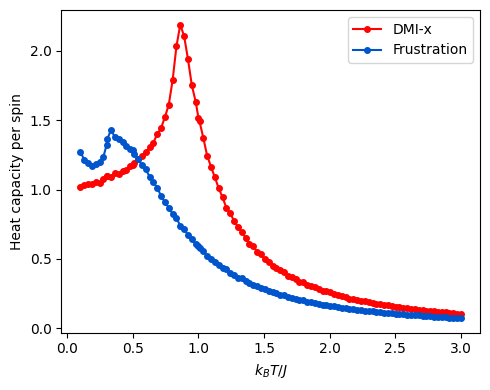

In [50]:
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(T, c_vs_t_dmi, '-o', color='#FF0202', label='DMI-x', markersize=4, linewidth=1.5)
ax.plot(T, c_vs_t_frustration, '-o', color='#0055CC', label='Frustration', markersize=4, linewidth=1.5)

ax.set_xlabel(r'$k_BT/J$')
ax.set_ylabel('Heat capacity per spin')
ax.legend()

fig.tight_layout()
fig.savefig('poster_heat_capacity.png', dpi=350, bbox_inches='tight')
fig.savefig('poster_heat_capacity.pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_1341/3587038455.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


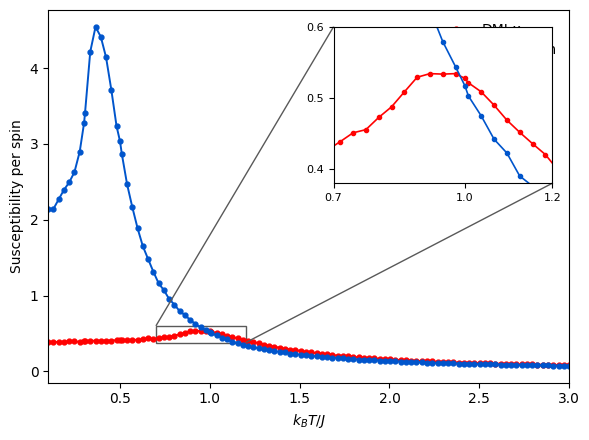

In [63]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

fig, ax = plt.subplots(figsize=(6, 4.5))

ax.plot(T, kai_vs_t_dmi, '-o', color='#FF0202', markersize=3.5, linewidth=1.4, label='DMI-x')
ax.plot(T, kai_vs_t_frustration, '-o', color='#0055CC', markersize=3.5, linewidth=1.4, label='Frustration')

ax.set_xlabel(r'$k_BT/J$')
ax.set_ylabel('Susceptibility per spin')
ax.legend(frameon=False)
ax.set_xlim(T.min(), T.max())

axins = inset_axes(ax, width="42%", height="42%", loc='upper right', borderpad=1.2)

axins.plot(T, kai_vs_t_dmi, '-o', color='#FF0202', markersize=3.0, linewidth=1.2)
axins.plot(T, kai_vs_t_frustration, '-o', color='#0055CC', markersize=3.0, linewidth=1.2)

x1, x2 = 0.80, 1.20
y1, y2 = 0.38, 0.58

axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)

axins.set_xticks([0.7, 1.2, 1.0])
axins.set_yticks([0.4, 0.5, 0.6])
axins.tick_params(labelsize=8)

mark_inset(ax, axins, loc1=2, loc2=4, fc='none', ec='0.35', lw=1.0)

fig.tight_layout()
fig.savefig('poster_susceptibility_zoom.png', dpi=350, bbox_inches='tight')
fig.savefig('poster_susceptibility_zoom.pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_1341/830488074.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 1, 0.97])


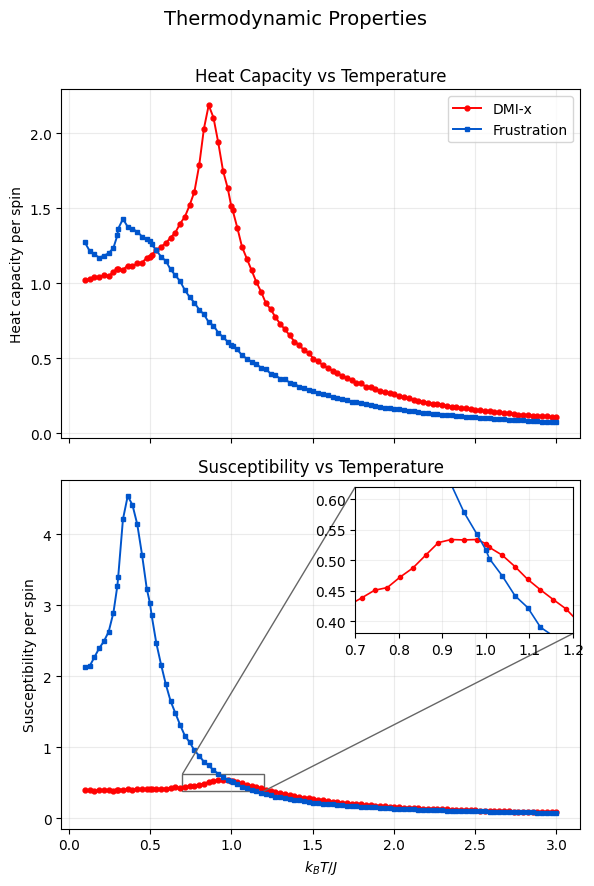

In [65]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(6, 9), sharex=True)

ax1 = axes[0]
ax1.plot(T, c_vs_t_dmi, color='#FF0202', marker='o', markersize=3.5, linewidth=1.4, label='DMI-x')
ax1.plot(T, c_vs_t_frustration, color='#0055CC', marker='s', markersize=3.5, linewidth=1.4, label='Frustration')

ax1.set_ylabel('Heat capacity per spin')
ax1.set_title('Heat Capacity vs Temperature')
ax1.legend(frameon=True)
ax1.grid(alpha=0.25)

ax2 = axes[1]
ax2.plot(T, kai_vs_t_dmi, color='#FF0202', marker='o', markersize=3.5, linewidth=1.4, label='DMI-x')
ax2.plot(T, kai_vs_t_frustration, color='#0055CC', marker='s', markersize=3.5, linewidth=1.4, label='Frustration')

ax2.set_xlabel(r'$k_B T/J$')
ax2.set_ylabel('Susceptibility per spin')
ax2.set_title('Susceptibility vs Temperature')
ax2.legend(frameon=True)
ax2.grid(alpha=0.25)

axins = inset_axes(ax2, width="42%", height="42%", loc='upper right')
axins.plot(T, kai_vs_t_dmi, color='#FF0202', marker='o', markersize=3, linewidth=1.2)
axins.plot(T, kai_vs_t_frustration, color='#0055CC', marker='s', markersize=3, linewidth=1.2)

axins.set_xlim(0.70, 1.20)
axins.set_ylim(0.38, 0.62)
axins.grid(alpha=0.20)

mark_inset(ax2, axins, loc1=2, loc2=4, fc='none', ec='0.4', lw=1.0)

fig.suptitle('Thermodynamic Properties', fontsize=14, y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.97])

fig.savefig('poster_thermodynamics_vertical.png', dpi=350, bbox_inches='tight')
fig.savefig('poster_thermodynamics_vertical.pdf', bbox_inches='tight')
plt.show()

In [28]:
def static_structure_factor(spins):
    replicas, nx, ny, _ = spins.shape
    F = np.fft.fftshift(np.fft.fft2(spins, axes=(1, 2)), axes=(1, 2))
    S_q = np.mean(np.sum(np.abs(F) ** 2, axis=-1), axis=0) / (nx * ny) ** 2
    qx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nx))
    qy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(ny))
    return qx, qy, S_q

In [29]:
def spin_chirality(spins):
    spin_x = np.roll(spins, -1, axis=1)
    chi_x = np.mean(np.cross(spins, spin_x), axis=(1, 2))
    return chi_x

In [30]:
rows = []
structure_factors = {}
for model, snapshots in [('dmi', spins_dmi), ('frustration', spins_frustration)]:
    for t in T_plot:
        spins = snapshots[float(t)]
        qx, qy, S_q = static_structure_factor(spins)
        structure_factors[(model, float(t))] = S_q
        iq = np.argmin(np.abs(qx - q0))
        iy = np.argmin(np.abs(qy))
        S_test = S_q.copy()
        S_test[L // 2, L // 2] = 0
        i, j = np.unravel_index(np.argmax(S_test), S_test.shape)
        chi_x = spin_chirality(spins)

        rows.append({ 'model': model, 'T': t, 'qx_peak': qx[i], 'qy_peak': qy[j], 'S_q0_over_N': S_q[iq, iy], 'S_max_over_N': S_test[i, j], 'chirality_x': np.mean(chi_x[:, 0]), 'chirality_norm': np.mean(np.linalg.norm(chi_x, axis=1)) })

df = pd.DataFrame(rows)
df.to_csv('magnetic_structure.csv', index=False)

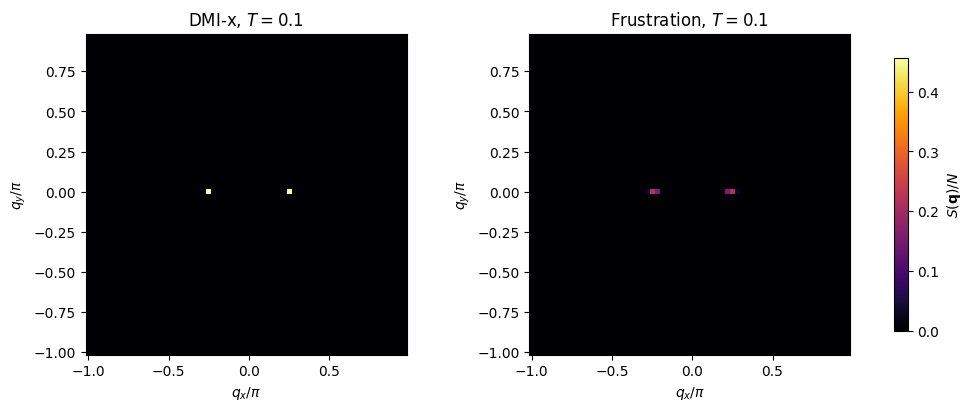

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, model, name in zip(axes, ['dmi', 'frustration'], ['DMI-x', 'Frustration']):
    Sq = structure_factors[(model, 0.1)]
    im = ax.pcolormesh(qx / np.pi, qy / np.pi, Sq.T, cmap='inferno', shading='auto', vmin=0, vmax=max(structure_factors[(m, 0.1)].max() for m in ['dmi', 'frustration']))
    ax.set_xlabel(r'$q_x/\pi$')
    ax.set_ylabel(r'$q_y/\pi$')
    ax.set_title(name + r', $T=0.1$')
    ax.set_aspect('equal')
fig.colorbar(im, ax=axes, shrink=0.85, label=r'$S(\mathbf{q})/N$')
fig.savefig('02_static_structure_factor.png', dpi=350, bbox_inches='tight')
fig.savefig('02_static_structure_factor.pdf', bbox_inches='tight')
plt.show()

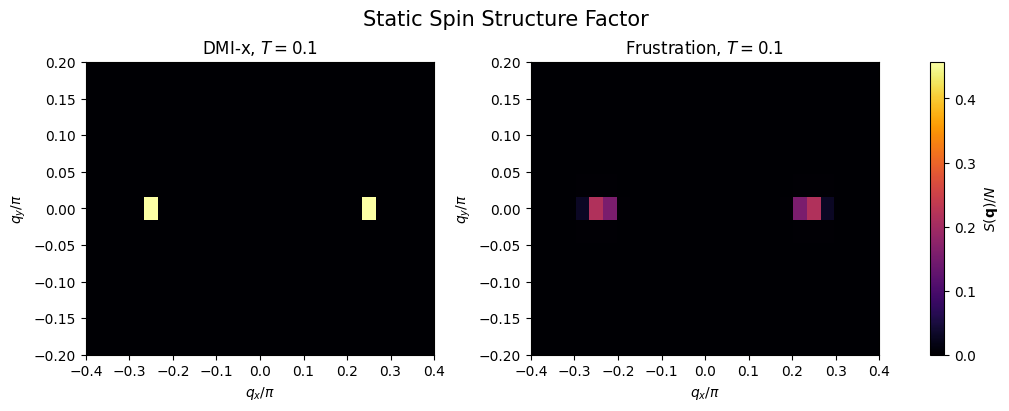

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
fig.suptitle('Static Spin Structure Factor', fontsize=15)
vmax = max(structure_factors[(model, 0.1)].max() for model in ['dmi', 'frustration'])

for ax, model, name in zip(axes, ['dmi', 'frustration'], ['DMI-x', 'Frustration']):
    Sq = structure_factors[(model, 0.1)]

    im = ax.pcolormesh(qx / np.pi, qy / np.pi, Sq.T, cmap='inferno', shading='auto', vmin=0, vmax=vmax)

    ax.set_xlim(-0.4, 0.4)
    ax.set_ylim(-0.2, 0.2)

    ax.set_xlabel(r'$q_x/\pi$')
    ax.set_ylabel(r'$q_y/\pi$')
    ax.set_title(name + r', $T=0.1$')

fig.colorbar(im, ax=axes, label=r'$S(\mathbf{q})/N$')

fig.savefig('static_structure_factor_zoom.png', dpi=350, bbox_inches='tight')
fig.savefig('static_structure_factor_zoom.pdf', bbox_inches='tight')
plt.show()

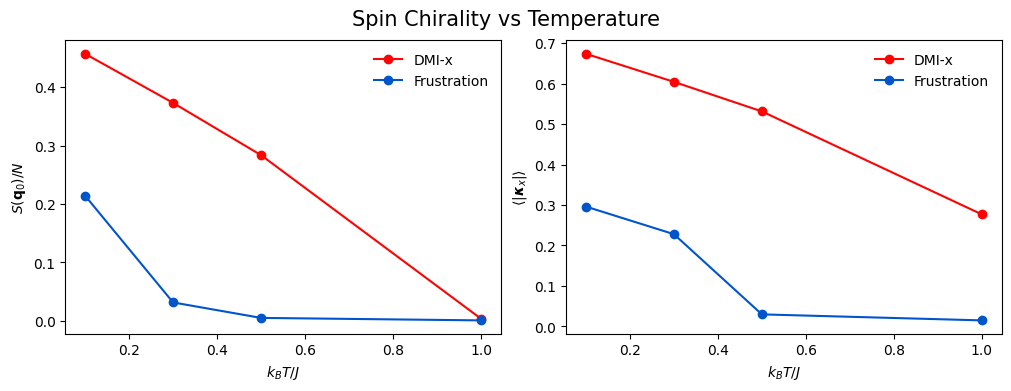

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
fig.suptitle('Spin Chirality vs Temperature', fontsize=15)
for model, name, color in [('dmi', 'DMI-x', '#FF0202'), ('frustration', 'Frustration', '#0055CC')]:
    part = df[df['model'] == model].sort_values('T')
    axes[0].plot(part['T'], part['S_q0_over_N'], 'o-', color=color, label=name)
    axes[1].plot(part['T'], part['chirality_norm'], 'o-', color=color, label=name)
axes[0].set_ylabel(r'$S(\mathbf{q}_0)/N$')
axes[1].set_ylabel(r'$\langle |\boldsymbol{\kappa}_x|\rangle$')
for ax in axes:
    ax.set_xlabel(r'$k_BT/J$')
    ax.legend(frameon=False)
fig.savefig('03_structure_chirality_vs_T.png', dpi=350, bbox_inches='tight')
fig.savefig('03_structure_chirality_vs_T.pdf', bbox_inches='tight')
plt.show()

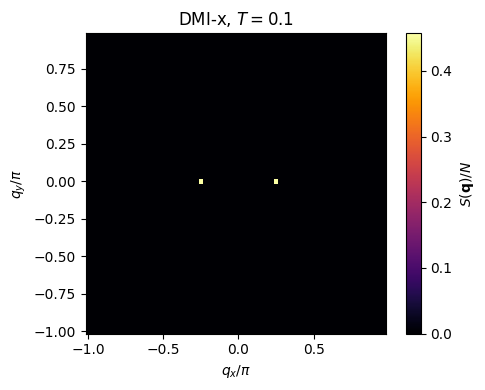

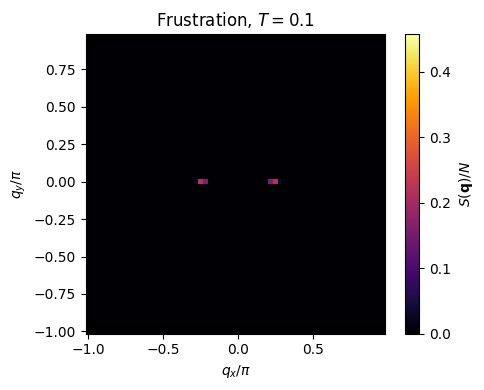

In [33]:
vmax = max(structure_factors[(model, 0.1)].max() for model in ['dmi', 'frustration'])

for model, name in [('dmi', 'DMI-x'), ('frustration', 'Frustration')]:
    fig, ax = plt.subplots(figsize=(5, 4))
    Sq = structure_factors[(model, 0.1)]
    im = ax.pcolormesh(qx / np.pi, qy / np.pi, Sq.T, cmap='inferno', shading='auto', vmin=0, vmax=vmax)
    ax.set_xlabel(r'$q_x/\pi$')
    ax.set_ylabel(r'$q_y/\pi$')
    ax.set_title(name + r', $T=0.1$')
    ax.set_aspect('equal')
    fig.colorbar(im, ax=ax, label=r'$S(\mathbf{q})/N$')
    fig.tight_layout()
    fig.savefig(f'poster_structure_factor_{model}.png', dpi=350, bbox_inches='tight')
    fig.savefig(f'poster_structure_factor_{model}.pdf', bbox_inches='tight')
    plt.show()

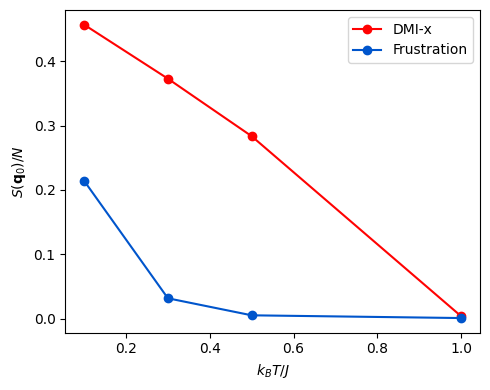

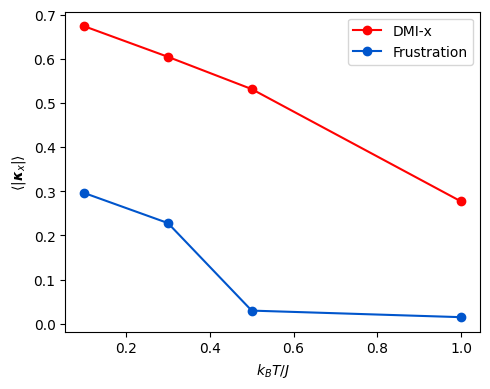

In [34]:
for column, ylabel, filename in [
    ('S_q0_over_N', r'$S(\mathbf{q}_0)/N$', 'poster_spiral_order'),
    ('chirality_norm', r'$\langle |\boldsymbol{\kappa}_x|\rangle$', 'poster_chirality')
]:
    fig, ax = plt.subplots(figsize=(5, 4))

    for model, name, color in [('dmi', 'DMI-x', '#FF0202'), ('frustration', 'Frustration', '#0055CC')]:
        part = df[df['model'] == model].sort_values('T')
        ax.plot(part['T'], part[column], 'o-', color=color, label=name)

    ax.set_xlabel(r'$k_BT/J$')
    ax.set_ylabel(ylabel)
    ax.legend()
    fig.tight_layout()
    fig.savefig(filename + '.png', dpi=350, bbox_inches='tight')
    fig.savefig(filename + '.pdf', bbox_inches='tight')
    plt.show()

In [35]:
def lswt_frequency_2d(kx, ky, model):
    cx = np.cos(kx)
    cy = np.cos(ky)
    cq = np.cos(q0)

    if model == 'dmi':
        lam = 2 * J * (1 + cq) + 2 * D * np.sin(q0)
        A = lam - 2 * J * (cx + cy)
        B = lam - 2 * ((J * cq + D * np.sin(q0)) * cx + J * cy)
    else:
        lam = 2 * J * (1 + cq) - 2 * J2 * np.cos(2 * q0)
        A = lam - 2 * J * (cx + cy) + 2 * J2 * np.cos(2 * kx)
        B = lam - 2 * J * (cq * cx + cy) + 2 * J2 * np.cos(2 * q0) * np.cos(2 * kx)

    return np.sqrt(np.maximum(A * B, 0))

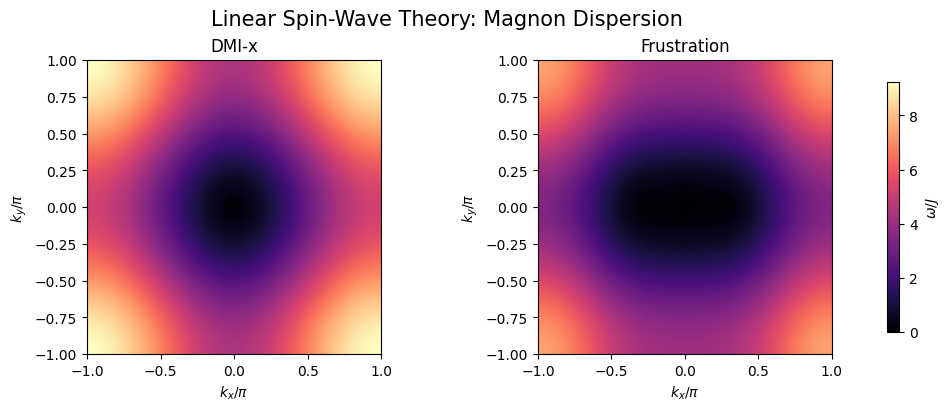

In [71]:
kx = np.linspace(-np.pi, np.pi, 601)
ky = np.linspace(-np.pi, np.pi, 601)
KX, KY = np.meshgrid(kx, ky, indexing='ij')

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
wd = lswt_frequency_2d(KX, KY, 'dmi')
wf = lswt_frequency_2d(KX, KY, 'frustration')
fig.suptitle('Linear Spin-Wave Theory: Magnon Dispersion', fontsize=15)
for ax, omega, name in zip(axes, [wd, wf], ['DMI-x', 'Frustration']):
    im = ax.pcolormesh(kx / np.pi, ky / np.pi, omega.T, shading='auto', cmap='magma', vmin=0, vmax=max(wd.max(), wf.max()))
    ax.set_title(name)
    ax.set_xlabel(r'$k_x/\pi$')
    ax.set_ylabel(r'$k_y/\pi$')
    ax.set_aspect('equal')
fig.colorbar(im, ax=axes, shrink=0.85, label=r'$\omega/J$')
fig.savefig('04_lswt_2d.png', dpi=350, bbox_inches='tight')
fig.savefig('04_lswt_2d.pdf', bbox_inches='tight')
plt.show()

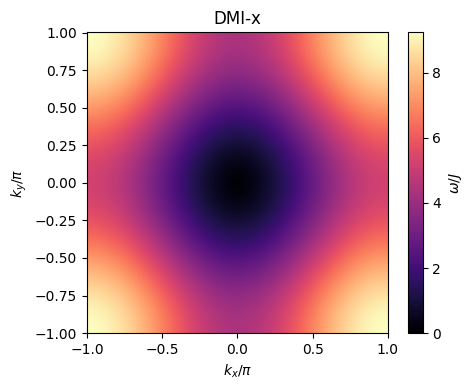

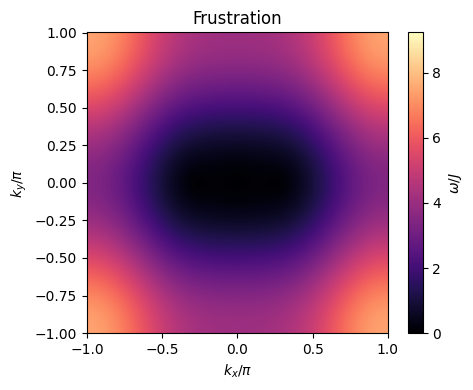

In [48]:
vmax = max(wd.max(), wf.max())

for model, w, name in [('dmi', wd, 'DMI-x'), ('frustration', wf, 'Frustration')]:
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.pcolormesh(kx / np.pi, ky / np.pi, w.T, cmap='magma', shading='auto', vmin=0, vmax=vmax)
    ax.set_xlabel(r'$k_x/\pi$')
    ax.set_ylabel(r'$k_y/\pi$')
    ax.set_title(name)
    ax.set_aspect('equal')
    fig.colorbar(im, ax=ax, label=r'$\omega/J$')
    fig.tight_layout()
    fig.savefig(f'poster_lswt_{model}.png', dpi=350, bbox_inches='tight')
    fig.savefig(f'poster_lswt_{model}.pdf', bbox_inches='tight')
    plt.show()

In [38]:
@cuda.jit
def rhs_gpu(spins, derivatives, model_id, J, J2, D, Bz):
    x, y, r = cuda.grid(3)

    nx = spins.shape[1]
    ny = spins.shape[2]

    if r >= spins.shape[0] or x >= nx or y >= ny:
        return

    xp = (x + 1) % nx
    xm = (x - 1 + nx) % nx
    yp = (y + 1) % ny
    ym = (y - 1 + ny) % ny

    sx = spins[r, x, y, 0]
    sy = spins[r, x, y, 1]
    sz = spins[r, x, y, 2]

    hx = J * ( spins[r, xp, y, 0] + spins[r, xm, y, 0] + spins[r, x, yp, 0] + spins[r, x, ym, 0] )

    hy = J * ( spins[r, xp, y, 1] + spins[r, xm, y, 1] + spins[r, x, yp, 1] + spins[r, x, ym, 1] )

    hz = J * ( spins[r, xp, y, 2] + spins[r, xm, y, 2] + spins[r, x, yp, 2] + spins[r, x, ym, 2] ) + Bz

    if model_id == 0:
        hy += D * (spins[r, xp, y, 2] - spins[r, xm, y, 2])
        hz -= D * (spins[r, xp, y, 1] - spins[r, xm, y, 1])
    else:
        xpp = (x + 2) % nx
        xmm = (x - 2 + nx) % nx

        hx -= J2 * (spins[r, xpp, y, 0] + spins[r, xmm, y, 0])
        hy -= J2 * (spins[r, xpp, y, 1] + spins[r, xmm, y, 1])
        hz -= J2 * (spins[r, xpp, y, 2] + spins[r, xmm, y, 2])

    derivatives[r, x, y, 0] = -(sy * hz - sz * hy)
    derivatives[r, x, y, 1] = -(sz * hx - sx * hz)
    derivatives[r, x, y, 2] = -(sx * hy - sy * hx)

In [39]:
@cuda.jit
def rk4_stage_gpu(spins, derivative, output, factor):
    x, y, r = cuda.grid(3)

    if r >= spins.shape[0] or x >= spins.shape[1] or y >= spins.shape[2]:
        return

    ax = spins[r, x, y, 0] + factor * derivative[r, x, y, 0]
    ay = spins[r, x, y, 1] + factor * derivative[r, x, y, 1]
    az = spins[r, x, y, 2] + factor * derivative[r, x, y, 2]

    inv = 1.0 / math.sqrt(ax * ax + ay * ay + az * az)

    output[r, x, y, 0] = ax * inv
    output[r, x, y, 1] = ay * inv
    output[r, x, y, 2] = az * inv

In [40]:
@cuda.jit
def rk4_finish_gpu(spins, k1, k2, k3, k4, dt):
    x, y, r = cuda.grid(3)

    if r >= spins.shape[0] or x >= spins.shape[1] or y >= spins.shape[2]:
        return

    factor = dt / 6.0

    ax = spins[r, x, y, 0] + factor * ( k1[r, x, y, 0] + 2.0 * k2[r, x, y, 0] + 2.0 * k3[r, x, y, 0] + k4[r, x, y, 0] )

    ay = spins[r, x, y, 1] + factor * ( k1[r, x, y, 1] + 2.0 * k2[r, x, y, 1] + 2.0 * k3[r, x, y, 1] + k4[r, x, y, 1] )

    az = spins[r, x, y, 2] + factor * ( k1[r, x, y, 2] + 2.0 * k2[r, x, y, 2] + 2.0 * k3[r, x, y, 2] + k4[r, x, y, 2] )

    inv = 1.0 / math.sqrt(ax * ax + ay * ay + az * az)

    spins[r, x, y, 0] = ax * inv
    spins[r, x, y, 1] = ay * inv
    spins[r, x, y, 2] = az * inv

In [41]:
def energy_per_spin(spins, model):
    xp = np.roll(spins, -1, axis=1)
    yp = np.roll(spins, -1, axis=2)

    energy = -J * np.sum(spins * (xp + yp), axis=(1, 2, 3), dtype=np.float64)

    if model == 'dmi':
        energy += D * np.sum(spins[:, :, :, 2] * xp[:, :, :, 1] - spins[:, :, :, 1] * xp[:, :, :, 2], axis=(1, 2), dtype=np.float64)
    else:
        xpp = np.roll(spins, -2, axis=1)
        energy += J2 * np.sum(spins * xpp, axis=(1, 2, 3), dtype=np.float64)

    energy -= B_z * np.sum(spins[:, :, :, 2], axis=(1, 2), dtype=np.float64)
    return energy / N

In [42]:
def rk4_step_cuda(d_spins, arrays, grid, model_id):
    d_stage, k1, k2, k3, k4 = arrays
    args = (model_id, np.float32(J), np.float32(J2), np.float32(D), np.float32(B_z))

    rhs_gpu[grid, BLOCK_ASD](d_spins, k1, *args)
    rk4_stage_gpu[grid, BLOCK_ASD](d_spins, k1, d_stage, np.float32(DT_ASD / 2))
    rhs_gpu[grid, BLOCK_ASD](d_stage, k2, *args)
    rk4_stage_gpu[grid, BLOCK_ASD](d_spins, k2, d_stage, np.float32(DT_ASD / 2))
    rhs_gpu[grid, BLOCK_ASD](d_stage, k3, *args)
    rk4_stage_gpu[grid, BLOCK_ASD](d_spins, k3, d_stage, np.float32(DT_ASD))
    rhs_gpu[grid, BLOCK_ASD](d_stage, k4, *args)
    rk4_finish_gpu[grid, BLOCK_ASD](d_spins, k1, k2, k3, k4, np.float32(DT_ASD))

In [43]:
def run_asd(model, starting_spins):
    model_id = 0 if model == 'dmi' else 1
    nrep, nx, ny, _ = starting_spins.shape
    grid = ( (nx + BLOCK_ASD[0] - 1) // BLOCK_ASD[0], (ny + BLOCK_ASD[1] - 1) // BLOCK_ASD[1], nrep )

    d_spins = cuda.to_device(np.ascontiguousarray(starting_spins, dtype=np.float32))
    arrays = [cuda.device_array_like(d_spins) for _ in range(5)]
    fourier_time = np.empty((nrep, N_SAMPLES_ASD, nx, ny, 3), dtype=np.complex64)

    E_initial = energy_per_spin(starting_spins, model)
    for sample in range(N_SAMPLES_ASD):
        if sample > 0:
            for _ in range(SAMPLE_EVERY_ASD):
                rk4_step_cuda(d_spins, arrays, grid, model_id)

        current = d_spins.copy_to_host()
        fourier_time[:, sample] = ( np.fft.fft2(current, axes=(1, 2)) / np.sqrt(nx * ny) ).astype(np.complex64)

    E_final = energy_per_spin(d_spins.copy_to_host(), model)
    drift = np.max(np.abs(E_final - E_initial) / np.maximum(np.abs(E_initial), 1e-10))
    return fourier_time, drift

In [44]:
def dynamical_structure_factor(fourier_time):
    nrep, nt, nx, ny, _ = fourier_time.shape
    sample_dt = DT_ASD * SAMPLE_EVERY_ASD
    window = np.hanning(nt).astype(np.float32)
    norm_factor = sample_dt / (nt * np.mean(window ** 2))
    omega_full = 2 * np.pi * np.fft.fftfreq(nt, sample_dt)
    positive = omega_full >= 0
    spectrum = np.zeros((np.count_nonzero(positive), nx, ny), dtype=np.float64)

    for component in range(3):
        series = fourier_time[..., component].copy()
        series -= series.mean(axis=1, keepdims=True)
        series *= window[None, :, None, None]
        transform = np.fft.fft(series, axis=1)[:, positive]
        spectrum += np.mean(np.abs(transform) ** 2, axis=0)

    spectrum *= norm_factor
    spectrum = np.fft.fftshift(spectrum, axes=(1, 2))
    qx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nx))
    qy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(ny))
    return qx, qy, omega_full[positive], spectrum.astype(np.float32)

In [73]:
spectra = {}
energy_drifts = []

for t in T_plot:
    spectra[float(t)] = {}

    for model, snapshots in [('dmi', spins_dmi), ('frustration', spins_frustration)]:
        spins = np.ascontiguousarray(snapshots[float(t)][:N_REPLICAS_ASD])
        fourier_time, drift = run_asd(model, spins)
        qx, qy, omega, S_qw = dynamical_structure_factor(fourier_time)
        spectra[float(t)][model] = S_qw
        energy_drifts.append({'T': float(t), 'model': model, 'energy_drift': drift})
        del fourier_time

    tag = str(float(t)).replace('.', 'p')
    np.savez_compressed( f'asd_T{tag}.npz', qx=qx, qy=qy, omega=omega, S_dmi=spectra[float(t)]['dmi'], S_frustration=spectra[float(t)]['frustration'], temperature=float(t), J=J, D=D, J2=J2, B_z=B_z )

pd.DataFrame(energy_drifts).to_csv('asd_energy_drift.csv', index=False)

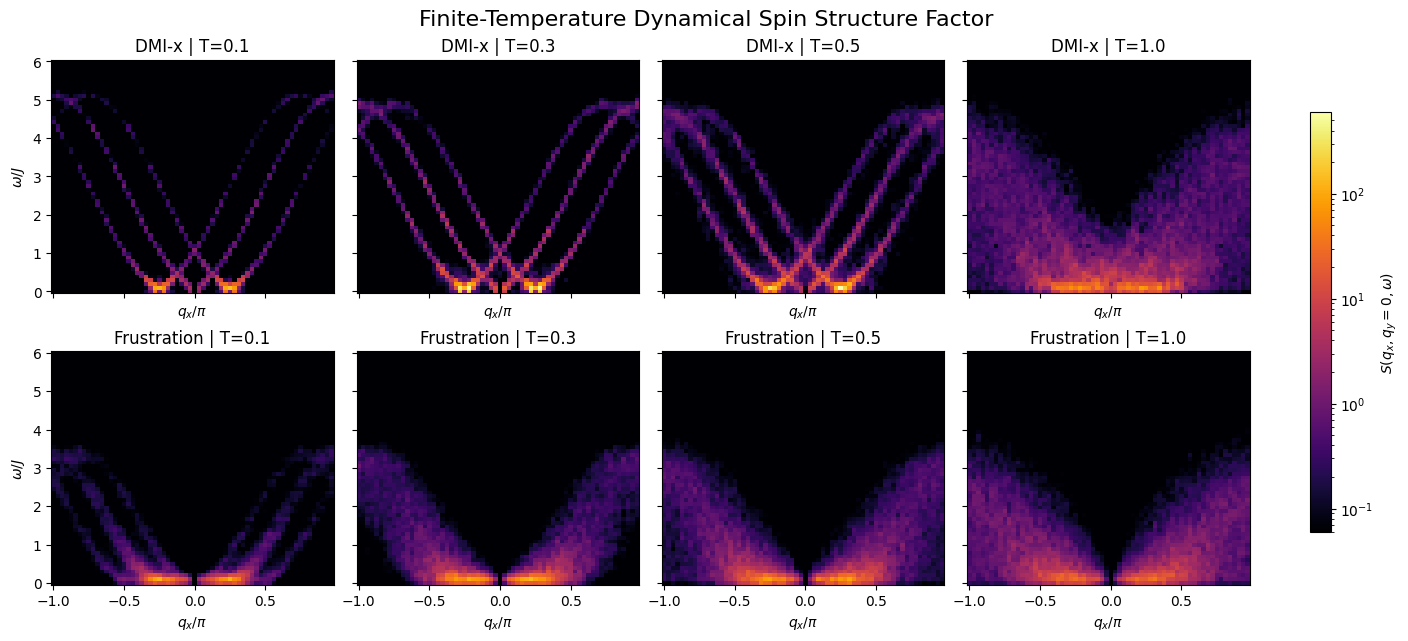

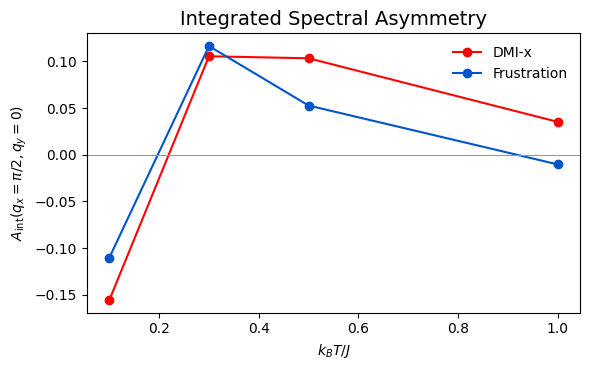

In [75]:
iy = np.argmin(np.abs(qy))
mask = (omega >= 0) & (omega <= 6.0)
peak = max(float(spectra[float(t)][model][mask, :, iy].max()) for t in T_plot for model in ['dmi', 'frustration'])

fig, axes = plt.subplots(2, 4, figsize=(14, 6.3), sharex=True, sharey=True, constrained_layout=True)
fig.suptitle('Finite-Temperature Dynamical Spin Structure Factor', fontsize=16)
for row, model in enumerate(['dmi', 'frustration']):
    for col, t in enumerate(T_plot):
        ax = axes[row, col]
        values = spectra[float(t)][model][mask, :, iy]
        im = ax.pcolormesh( qx / np.pi, omega[mask], values, shading='auto', cmap='inferno', norm=LogNorm(vmin=max(peak * 1e-4, 1e-10), vmax=peak) )
        ax.set_title(f'{"DMI-x" if model == "dmi" else "Frustration"} | T={t:.1f}')
        ax.set_xlabel(r'$q_x/\pi$')
        if col == 0:
            ax.set_ylabel(r'$\omega/J$')
fig.colorbar(im, ax=axes, shrink=0.8, label=r'$S(q_x,q_y=0,\omega)$')
fig.savefig('05_asd_finite_temperature.png', dpi=350, bbox_inches='tight')
fig.savefig('05_asd_finite_temperature.pdf', bbox_inches='tight')
plt.show()

rows = []
ixp = np.argmin(np.abs(qx - np.pi / 2))
ixm = np.argmin(np.abs(qx + np.pi / 2))
for t in T_plot:
    for model in ['dmi', 'frustration']:
        sqw = spectra[float(t)][model]
        positive_intensity = np.sum(sqw[1:, ixp, iy])
        negative_intensity = np.sum(sqw[1:, ixm, iy])
        A = (positive_intensity - negative_intensity) / (positive_intensity + negative_intensity + 1e-12)
        rows.append({'T': float(t), 'model': model, 'A_integrated': A})

df_asymmetry = pd.DataFrame(rows)
df_asymmetry.to_csv('spectral_asymmetry.csv', index=False)

fig, ax = plt.subplots(figsize=(6, 3.8))
for model, name, color in [('dmi', 'DMI-x', '#FF0202'), ('frustration', 'Frustration', '#0055CC')]:
    part = df_asymmetry[df_asymmetry['model'] == model]
    ax.plot(part['T'], part['A_integrated'], 'o-', color=color, label=name)
ax.axhline(0, color='0.6', lw=0.8)
ax.set_xlabel(r'$k_BT/J$')
ax.set_ylabel(r'$A_{\mathrm{int}}(q_x=\pi/2,q_y=0)$')
ax.legend(frameon=False)
ax.set_title('Integrated Spectral Asymmetry', fontsize=14)
fig.tight_layout()
fig.savefig('06_spectral_asymmetry.png', dpi=350, bbox_inches='tight')
fig.savefig('06_spectral_asymmetry.pdf', bbox_inches='tight')
plt.show()

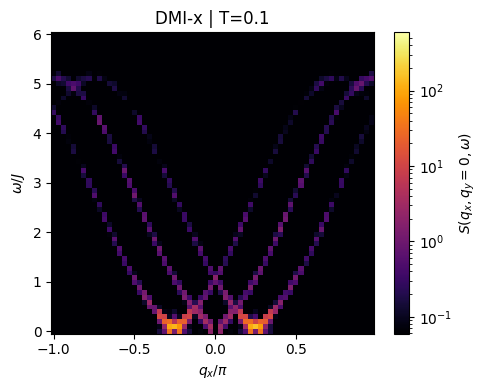

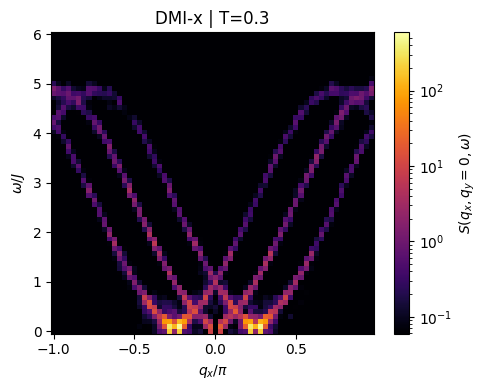

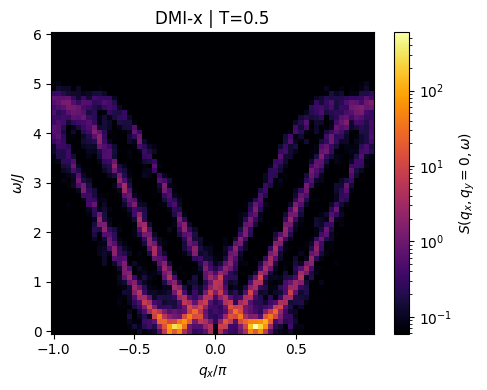

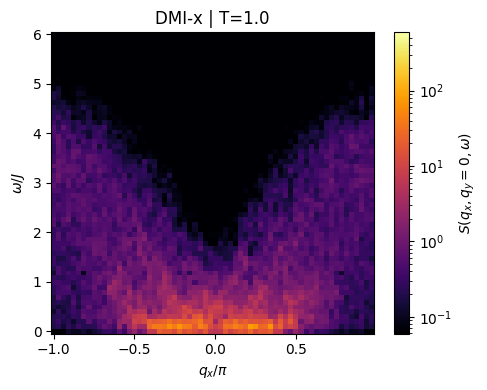

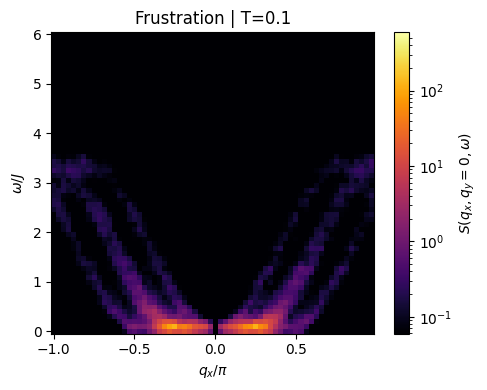

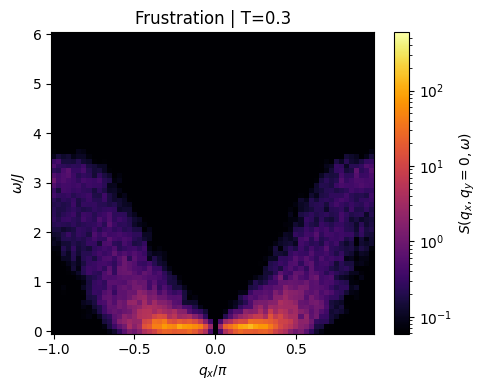

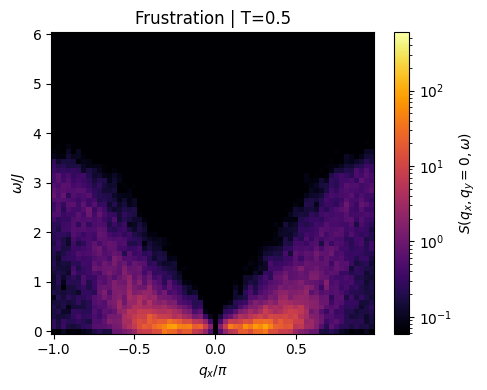

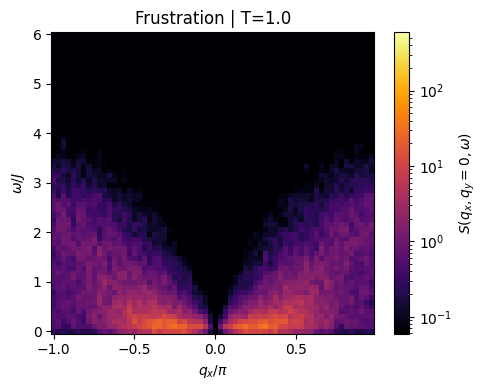

In [47]:
iy = np.argmin(np.abs(qy))
mask = (omega >= 0) & (omega <= 6.0)
peak = max(float(spectra[float(t)][model][mask, :, iy].max()) for t in T_plot for model in ['dmi', 'frustration'])

for model, name in [('dmi', 'DMI-x'), ('frustration', 'Frustration')]:
    for t in T_plot:
        fig, ax = plt.subplots(figsize=(5, 4))
        values = spectra[float(t)][model][mask, :, iy]
        im = ax.pcolormesh(qx / np.pi, omega[mask], values, cmap='inferno', shading='auto', norm=LogNorm(vmin=max(peak * 1e-4, 1e-10), vmax=peak))
        ax.set_xlabel(r'$q_x/\pi$')
        ax.set_ylabel(r'$\omega/J$')
        ax.set_title(f'{name} | T={t:.1f}')
        fig.colorbar(im, ax=ax, label=r'$S(q_x,q_y=0,\omega)$')
        fig.tight_layout()
        tag = str(float(t)).replace('.', 'p')
        fig.savefig(f'poster_asd_{model}_T{tag}.png', dpi=350, bbox_inches='tight')
        fig.savefig(f'poster_asd_{model}_T{tag}.pdf', bbox_inches='tight')
        plt.show()